# Ceylon Tea Production Forecasting - Ensemble Learning Comparison
**Bagging vs Boosting vs Stacking vs Hybrid models on official Sri Lanka Tea Board data (2021–2025)**

**Goal:** Predict next month's made-tea production (million kg) for **High, Medium and Low grown** tea and compare 10 models from 7 families:

| Family | Models |
|---|---|
| Baseline | Seasonal naïve (same month last year) |
| Bagging | Random Forest, Extra Trees |
| Boosting | Gradient Boosting, LightGBM, CatBoost |
| Neural network | ANN (MLP) |
| Stacking | RF + GB + LightGBM + CatBoost → Ridge meta-learner |
| Time series | SARIMA |
| Hybrid | SARIMA + Random Forest (RF learns SARIMA's residuals) |

**Data source:** Sri Lanka Tea Board — *Revised Tea Production* reports (monthly by elevation), 2021–2025, srilankateaboard.lk. 2022 and 2023 monthly values were derived from the Board's revised cumulative tables. 2019–2020 were excluded because the month order in those PDFs could not be verified.

**Workflow:** this notebook trains and evaluates the models, then **exports the trained models** (`tea_model_bundle.zip`). The local Streamlit dashboard (`app.py`) loads that bundle to show the results and make predictions without retraining.

> **AI-use declaration:** Parts of the code in this notebook (data preparation, model training, plots and model export) were generated with the help of Claude (Anthropic), a generative AI tool, and then reviewed, run and interpreted by me.

## 1. Setup

In [ ]:
!pip -q install catboost
import io, os, json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, lightgbm, catboost, statsmodels, joblib
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
VERSIONS = {'scikit-learn': sklearn.__version__, 'lightgbm': lightgbm.__version__,
            'catboost': catboost.__version__, 'statsmodels': statsmodels.__version__}
print(VERSIONS)

{'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'statsmodels': '0.15.0'}


## 2. Load the data
The CSV is embedded so the notebook runs anywhere. Values are in kg; we work in **million kg (Mn kg)**.

In [ ]:
CSV = """Date,Year,Month,MonthName,High,Medium,Low,Total,Orthodox,CTC,Green
2021-01-01,2021,1,Jan,4863159,3310478,15004174,23177812,20953875,2057118,166819
2021-02-01,2021,2,Feb,4649644,3654869,14220741,22525254,20287865,2072262,165127
2021-03-01,2021,3,Mar,6557893,5006587,17245432,28809912,26085908,2477632,246372
2021-04-01,2021,4,Apr,6983142,5567591,17482026,30032759,27252404,2586593,193762
2021-05-01,2021,5,May,7632490,5999070,17468926,31100485,28118873,2759582,222031
2021-06-01,2021,6,Jun,5930981,4521521,15615515,26068017,23727163,2086701,254153
2021-07-01,2021,7,Jul,5848256,4847552,15688977,26384786,23967350,2162850,254586
2021-08-01,2021,8,Aug,5062743,3877307,14932599,23872650,21652956,1975941,243754
2021-09-01,2021,9,Sep,4203944,3671696,14875734,22751374,20615679,1895103,240592
2021-10-01,2021,10,Oct,4900308,4054865,15221909,24177082,21697637,2243907,235539
2021-11-01,2021,11,Nov,4127663,3237282,12699761,20064705,18038052,1871895,154759
2021-12-01,2021,12,Dec,4566347,3236898,12720340,20523585,18323583,2005120,194882
2022-01-01,2022,1,Jan,5559378,3822935,13486162,22868475,20408260,2235738,224477
2022-02-01,2022,2,Feb,4391606,2778512,11054060,18224178,16371260,1705079,147839
2022-03-01,2022,3,Mar,5189661,3425521,13627874,22243057,20299555,1826249,117253
2022-04-01,2022,4,Apr,5781960,4093294,13370694,23245947,21207825,1941574,96548
2022-05-01,2022,5,May,6744984,4785022,14912173,26442178,23869941,2423330,148907
2022-06-01,2022,6,Jun,4118550,2933880,13225507,20277938,18619420,1526633,131884
2022-07-01,2022,7,Jul,4092673,2915966,12915289,19923928,18110311,1693452,120166
2022-08-01,2022,8,Aug,3421665,2453545,12442763,18317974,16396718,1812352,108904
2022-09-01,2022,9,Sep,4774699,3508565,12947402,21230665,19052945,2002616,175104
2022-10-01,2022,10,Oct,3993507,3038140,11960012,18991658,17072238,1749187,170233
2022-11-01,2022,11,Nov,4401090,3053036,12910360,20364487,18329789,1833196,201502
2022-12-01,2022,12,Dec,4483553,2914969,12309987,19708509,17700870,1840488,167152
2023-01-01,2023,1,Jan,3630805,2501989,12338824,18471618,16670137,1639848,161634
2023-02-01,2023,2,Feb,4287366,3108622,11361062,18757050,16950082,1616531,190435
2023-03-01,2023,3,Mar,4971556,3609887,13704259,22285702,20123468,1914025,248211
2023-04-01,2023,4,Apr,6429671,4517489,14290647,25237807,22688522,2324591,224694
2023-05-01,2023,5,May,7228330,4835698,14761062,26825090,24033279,2583087,208723
2023-06-01,2023,6,Jun,5608026,4075838,13404612,23088476,20846943,2080610,160923
2023-07-01,2023,7,Jul,4496145,3336171,13735121,21567437,19664037,1763094,140306
2023-08-01,2023,8,Aug,4219343,2985111,11153639,18358092,16539024,1651377,167691
2023-09-01,2023,9,Sep,4297243,3038122,11568078,18903445,17074086,1625789,203571
2023-10-01,2023,10,Oct,4255942,3914364,14829954,23000259,20935800,1861025,203432
2023-11-01,2023,11,Nov,4630411,3449222,11705041,19784674,17871815,1719704,193155
2023-12-01,2023,12,Dec,4585021,2965383,12258591,19808996,17790508,1837683,180807
2024-01-01,2024,1,Jan,3546023,2650739,12535537,18732299,16811474,1772824,148001
2024-02-01,2024,2,Feb,4465966,3802550,11826255,20094771,18123467,1786034,185270
2024-03-01,2024,3,Mar,4811210,4088136,10748398,19647743,17564438,1906575,176731
2024-04-01,2024,4,Apr,4425116,3786584,13469390,21681090,19786768,1743177,151145
2024-05-01,2024,5,May,5746665,4595751,14303997,24646413,22333782,2123852,188780
2024-06-01,2024,6,Jun,4793978,4660015,13699828,23153820,20787632,2137993,228196
2024-07-01,2024,7,Jul,5430816,4265892,13495086,23191795,20892044,2062821,236930
2024-08-01,2024,8,Aug,3864578,3724774,13747128,21336480,19276681,1876654,183145
2024-09-01,2024,9,Sep,4751435,4145246,15490793,24387474,21985669,2212025,189780
2024-10-01,2024,10,Oct,4138687,3607291,13537451,21283429,19099312,2004575,179542
2024-11-01,2024,11,Nov,5123295,4297668,13306648,22727612,20399948,2124048,203616
2024-12-01,2024,12,Dec,4604235,3754519,13452149,21810903,19683352,1937243,190307
2025-01-01,2025,1,Jan,4715949,3462305,13447716,21625970,19593887,1840877,191206
2025-02-01,2025,2,Feb,3473345,2578729,9705699,15757773,14188561,1411007,158205
2025-03-01,2025,3,Mar,5696422,5085884,13995509,24777815,22408778,2131826,237211
2025-04-01,2025,4,Apr,6353885,5348983,14763645,26466513,23790017,2456073,220423
2025-05-01,2025,5,May,5964616,5036136,14435047,25435799,22946775,2274322,214702
2025-06-01,2025,6,Jun,4259981,3944678,13504885,21709545,19684652,1840432,184460
2025-07-01,2025,7,Jul,3976308,3765562,13745590,21487460,19173198,2091926,222337
2025-08-01,2025,8,Aug,3717241,3237781,12761360,19716382,17656431,1875632,184319
2025-09-01,2025,9,Sep,4948137,4162742,13069211,22180090,19765481,2226203,188406
2025-10-01,2025,10,Oct,3932159,3513000,14545812,21990970,19696407,2118369,176195
2025-11-01,2025,11,Nov,4757928,3963824,12989032,21710784,19289619,2228311,192855
2025-12-01,2025,12,Dec,4700235,3606762,13449662,21756659,19302799,2256800,197060"""
df = pd.read_csv(io.StringIO(CSV), parse_dates=['Date'])
print(df.shape)
df.head()

(60, 11)


,Date,Year,Month,MonthName,High,Medium,Low,Total,Orthodox,CTC,Green
0,2021-01-01,2021,1,Jan,4863159,3310478,15004174,23177812,20953875,2057118,166819
1,2021-02-01,2021,2,Feb,4649644,3654869,14220741,22525254,20287865,2072262,165127
2,2021-03-01,2021,3,Mar,6557893,5006587,17245432,28809912,26085908,2477632,246372
3,2021-04-01,2021,4,Apr,6983142,5567591,17482026,30032759,27252404,2586593,193762
4,2021-05-01,2021,5,May,7632490,5999070,17468926,31100485,28118873,2759582,222031


## 3. Exploratory data analysis

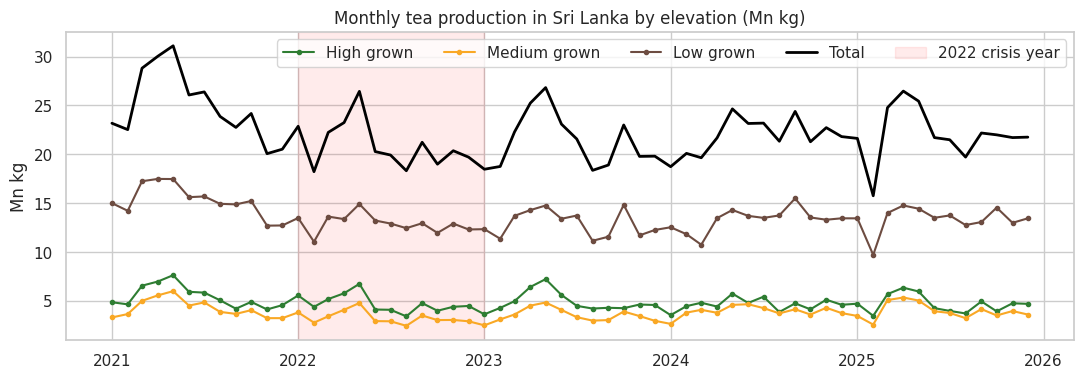

In [ ]:
fig, ax = plt.subplots(figsize=(13,4))
for c, col in zip(['High','Medium','Low'], ['#2E7D32','#F9A825','#6D4C41']):
    ax.plot(df.Date, df[c]/1e6, marker='o', ms=3, label=f'{c} grown', color=col)
ax.plot(df.Date, df.Total/1e6, color='black', lw=2, label='Total')
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'), color='red', alpha=.08, label='2022 crisis year')
ax.set_title('Monthly tea production in Sri Lanka by elevation (Mn kg)'); ax.set_ylabel('Mn kg'); ax.legend(ncol=5)
plt.show()

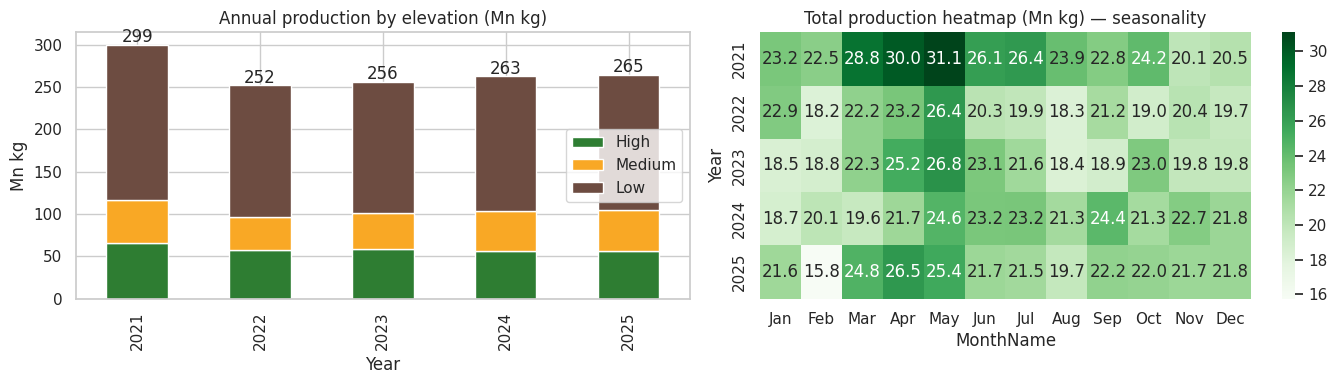

Share of production 2021-2025 (%): {'High': 22.0, 'Medium': 17.1, 'Low': 60.9}
Year-on-year change in total (%): {2021: nan, 2022: -15.9, 2023: 1.7, 2024: 2.6, 2025: 0.7}


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
yearly = df.groupby('Year')[['High','Medium','Low']].sum()/1e6
yearly.plot(kind='bar', stacked=True, ax=axes[0], color=['#2E7D32','#F9A825','#6D4C41'])
axes[0].set_title('Annual production by elevation (Mn kg)'); axes[0].set_ylabel('Mn kg')
for i, v in enumerate(yearly.sum(axis=1)): axes[0].text(i, v+3, f'{v:.0f}', ha='center')
sns.heatmap(df.pivot(index='Year', columns='MonthName', values='Total')[['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']]/1e6,
            annot=True, fmt='.1f', cmap='Greens', ax=axes[1])
axes[1].set_title('Total production heatmap (Mn kg) — seasonality'); plt.tight_layout(); plt.show()
print('Share of production 2021-2025 (%):', (df[['High','Medium','Low']].sum()/df.Total.sum()*100).round(1).to_dict())
print('Year-on-year change in total (%):', (df.groupby('Year').Total.sum().pct_change()*100).round(1).to_dict())

**Observations**
- Low grown tea is about 61% of total output, so it dominates total production.
- Production fell sharply in **2022** (≈ –16% vs 2021). The Sri Lanka Tea Board linked weak harvests since 2021 to the fertiliser crisis and the herbicide ban. Output recovered slowly in 2023–2025.
- Clear seasonality: **March–May** is usually the peak; February is often low.

## 4. Feature engineering
The three elevations are stacked into one table (**long format**), giving the models 3× more rows.
Features for month *t* use only information available **before** month *t* (no leakage):
- `lag1, lag2, lag3` – production in the previous 1–3 months
- `lag12` – same month last year (seasonality)
- `roll3` – mean of the previous 3 months
- `month_sin, month_cos` – cyclical month encoding
- `t` – time index, `elev_*` – elevation one-hot

**Time-based split:** train = Jan 2022 – Dec 2024, test = **Jan – Dec 2025** (one-step-ahead forecasts). A random split would leak future information into training.

In [ ]:
FEATURES = ['lag1','lag2','lag3','lag12','roll3','month_sin','month_cos','t','elev_High','elev_Medium','elev_Low']

def make_features(df):
    long = df.melt(id_vars=['Date','Year','Month'], value_vars=['High','Medium','Low'],
                   var_name='Elevation', value_name='Prod')
    long['Prod'] = long['Prod']/1e6
    long = long.sort_values(['Elevation','Date']).reset_index(drop=True)
    g = long.groupby('Elevation')['Prod']
    for L in [1,2,3,12]:
        long[f'lag{L}'] = g.shift(L)
    long['roll3'] = g.transform(lambda s: s.shift(1).rolling(3).mean())
    long['month_sin'] = np.sin(2*np.pi*long.Month/12)
    long['month_cos'] = np.cos(2*np.pi*long.Month/12)
    long['t'] = (long.Year-2021)*12 + long.Month - 1
    for e in ['High','Medium','Low']:
        long[f'elev_{e}'] = (long.Elevation==e).astype(int)
    return long

long = make_features(df)
data = long.dropna().sort_values(['Date','Elevation']).reset_index(drop=True)
train = data[data.Date < '2025-01-01']; test = data[data.Date >= '2025-01-01']
X_tr, y_tr, X_te, y_te = train[FEATURES], train.Prod, test[FEATURES], test.Prod
print(f'Train rows: {len(train)}  |  Test rows: {len(test)}')
data[['Date','Elevation','Prod']+FEATURES].head()

Train rows: 108  |  Test rows: 36


,Date,Elevation,Prod,lag1,lag2,lag3,lag12,roll3,month_sin,month_cos,t,elev_High,elev_Medium,elev_Low
0,2022-01-01,High,5.559378,4.566347,4.127663,4.900308,4.863159,4.531439,0.500000,0.866025,12,1,0,0
1,2022-01-01,Low,13.486162,12.720340,12.699761,15.221909,15.004174,13.547337,0.500000,0.866025,12,0,0,1
2,2022-01-01,Medium,3.822935,3.236898,3.237282,4.054865,3.310478,3.509682,0.500000,0.866025,12,0,1,0
3,2022-02-01,High,4.391606,5.559378,4.566347,4.127663,4.649644,4.751129,0.866025,0.500000,13,1,0,0
4,2022-02-01,Low,11.054060,13.486162,12.720340,12.699761,14.220741,12.968754,0.866025,0.500000,13,0,0,1


## 5. Machine learning models — bagging, boosting, neural network, stacking
- **Random Forest / Extra Trees (bagging):** many trees trained in parallel on random samples; predictions are averaged → reduces **variance**. Extra Trees also picks split points at random.
- **Gradient Boosting / LightGBM / CatBoost (boosting):** trees built one after another, each fitting the remaining error → reduces **bias**.
- **ANN (MLP):** a small neural network (two hidden layers).
- **Stacking:** RF, GB, LightGBM and CatBoost make predictions; a Ridge regression meta-learner learns how to combine them.

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

rf   = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED)
gb   = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED)
lgbm = LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=8, min_child_samples=5, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
cat  = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=4, random_seed=SEED, verbose=0)

MODELS = {
    'Random Forest':     rf,
    'Extra Trees':       ExtraTreesRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED),
    'Gradient Boosting': gb,
    'LightGBM':          lgbm,
    'CatBoost':          cat,
    'ANN (MLP)':         TransformedTargetRegressor(
                             regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32,16), alpha=0.01,
                                                                                    max_iter=5000, random_state=SEED)),
                             transformer=StandardScaler()),
    'Stacking (RF+GB+LGBM+Cat→Ridge)': StackingRegressor(
        estimators=[('rf',clone(rf)),('gb',clone(gb)),('lgbm',clone(lgbm)),('cat',clone(cat))],
        final_estimator=RidgeCV(alphas=np.logspace(-3,3,20)), cv=KFold(5)),
}
FAMILY = {'Seasonal Naive (lag-12)':'Baseline', 'Random Forest':'Bagging', 'Extra Trees':'Bagging',
          'Gradient Boosting':'Boosting', 'LightGBM':'Boosting', 'CatBoost':'Boosting', 'ANN (MLP)':'Neural network',
          'Stacking (RF+GB+LGBM+Cat→Ridge)':'Stacking', 'SARIMA':'Time series', 'Hybrid SARIMA + RF':'Hybrid'}

pred = test[['Date','Elevation','Prod']].rename(columns={'Prod':'Actual'}).reset_index(drop=True)
pred['Seasonal Naive (lag-12)'] = test['lag12'].values
fitted = {}
for name, m in MODELS.items():
    fitted[name] = clone(m).fit(X_tr, y_tr)
    pred[name] = fitted[name].predict(X_te)
    print(f'✓ {name}')

✓ Random Forest
✓ Extra Trees
✓ Gradient Boosting
✓ LightGBM
✓ CatBoost
✓ ANN (MLP)
✓ Stacking (RF+GB+LGBM+Cat→Ridge)


## 6. Time series model and hybrid
**SARIMA(1,0,1)(0,1,1)₁₂** is fitted separately for each elevation on 2021–2024. For 2025 we produce one-step-ahead forecasts using the *training* parameters (no refitting on test data), so the comparison with the ML models is fair.

**Hybrid — SARIMA + Random Forest:** SARIMA captures trend and seasonality; a Random Forest then learns the **non-linear part SARIMA misses** (its residuals). Final forecast = SARIMA forecast + RF residual forecast.

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
ORDER, SORDER = (1,0,1), (0,1,1,12)
def sarima(series):
    return SARIMAX(series, order=ORDER, seasonal_order=SORDER, enforce_stationarity=False, enforce_invertibility=False)

sarima_onestep = {}
for e in ['High','Medium','Low']:
    s = (df.set_index('Date')[e]/1e6).asfreq('MS')
    res = sarima(s[:'2024-12-01']).fit(disp=False)
    sarima_onestep[e] = sarima(s).filter(res.params).get_prediction(start='2022-01-01', dynamic=False).predicted_mean
    print(f'✓ SARIMA {e}:  AIC = {res.aic:.1f}')

def sarima_for(frame):
    return np.array([sarima_onestep[e].loc[d] for d, e in zip(frame.Date, frame.Elevation)])

sar_tr, sar_te = sarima_for(train), sarima_for(test)
pred['SARIMA'] = sar_te
def new_resid_rf(): return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED)
rf_resid = new_resid_rf().fit(X_tr, y_tr.values - sar_tr)
pred['Hybrid SARIMA + RF'] = sar_te + rf_resid.predict(X_te)
pred.head()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


✓ SARIMA High:  AIC = 49.7


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


✓ SARIMA Medium:  AIC = 44.1


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


✓ SARIMA Low:  AIC = 79.7


,Date,Elevation,Actual,Seasonal Naive (lag-12),Random Forest,Extra Trees,Gradient Boosting,LightGBM,CatBoost,ANN (MLP),Stacking (RF+GB+LGBM+Cat→Ridge),SARIMA,Hybrid SARIMA + RF
0,2025-01-01,High,4.715949,3.546023,4.089560,4.130604,4.349305,4.166833,4.599518,4.534056,3.985766,3.860124,4.006271
1,2025-01-01,Low,13.447716,12.535537,13.053386,13.204762,12.891740,12.199352,12.880216,13.536815,13.560542,12.801302,12.967427
2,2025-01-01,Medium,3.462305,2.650739,3.839370,3.897557,3.881370,3.834019,3.721418,3.389601,3.770317,3.095626,3.494723
3,2025-02-01,High,3.473345,4.465966,4.511406,4.509411,4.303939,4.115186,4.561331,5.111372,4.744682,4.676855,4.675063
4,2025-02-01,Low,9.705699,11.826255,13.432344,12.966019,13.209277,13.068325,12.862764,13.632846,13.631872,10.978231,11.793397


## 7. Results — model comparison on 2025 (unseen) data

In [ ]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p),
            'MAPE %': np.mean(np.abs((y-p)/y))*100, 'R²': r2_score(y, p)}
MODEL_COLS = [c for c in pred.columns if c not in ['Date','Elevation','Actual']]
results = pd.DataFrame({m: metrics(pred.Actual, pred[m]) for m in MODEL_COLS}).T
results.insert(0, 'Family', [FAMILY[m] for m in results.index])
results = results.sort_values('RMSE')
results.round(3).style.background_gradient(subset=['RMSE','MAE','MAPE %'], cmap='RdYlGn_r')\
                      .background_gradient(subset=['R²'], cmap='RdYlGn')

,Family,RMSE,MAE,MAPE %,R²
SARIMA,Time series,0.700000,0.571000,10.384000,0.974000
Hybrid SARIMA + RF,Hybrid,0.745000,0.602000,11.156000,0.971000
Extra Trees,Bagging,0.890000,0.642000,11.082000,0.959000
CatBoost,Boosting,0.894000,0.638000,10.839000,0.958000
LightGBM,Boosting,0.944000,0.698000,11.180000,0.954000
Gradient Boosting,Boosting,0.961000,0.714000,11.548000,0.952000
Random Forest,Bagging,0.966000,0.682000,11.660000,0.951000
Stacking (RF+GB+LGBM+Cat→Ridge),Stacking,1.049000,0.751000,12.998000,0.943000
Seasonal Naive (lag-12),Baseline,1.081000,0.789000,12.943000,0.939000
ANN (MLP),Neural network,1.242000,1.012000,17.688000,0.920000


In [ ]:
by_elev = pd.concat({e: pd.DataFrame({m: metrics(g.Actual, g[m]) for m in MODEL_COLS}).T
                     for e, g in pred.groupby('Elevation')}, names=['Elevation','Model']).reset_index()
print('RMSE (Mn kg) by elevation:')
by_elev.pivot(index='Model', columns='Elevation', values='RMSE').loc[results.index, ['High','Medium','Low']].round(3)

RMSE (Mn kg) by elevation:


Elevation,High,Medium,Low
SARIMA,0.727,0.663,0.708
Hybrid SARIMA + RF,0.769,0.652,0.806
Extra Trees,0.627,0.761,1.184
CatBoost,0.715,0.602,1.235
LightGBM,0.671,0.670,1.333
Gradient Boosting,0.712,0.647,1.358
Random Forest,0.730,0.736,1.314
Stacking (RF+GB+LGBM+Cat→Ridge),0.852,0.822,1.379
Seasonal Naive (lag-12),0.892,0.760,1.461
ANN (MLP),0.955,1.046,1.619


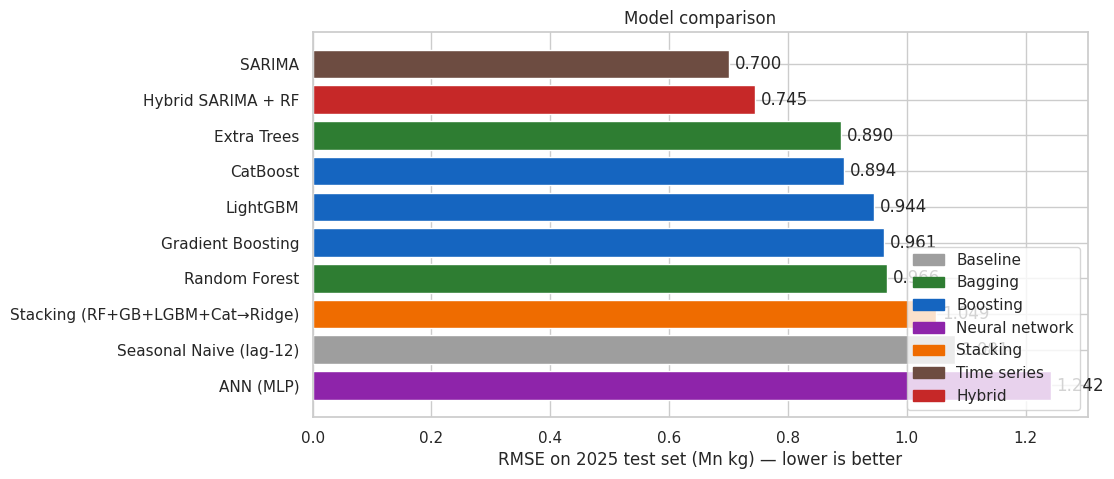

In [ ]:
FAM_COL = {'Baseline':'#9E9E9E','Bagging':'#2E7D32','Boosting':'#1565C0','Neural network':'#8E24AA',
           'Stacking':'#EF6C00','Time series':'#6D4C41','Hybrid':'#C62828'}
r = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(r.index, r.RMSE, color=[FAM_COL[f] for f in r.Family])
for i, v in enumerate(r.RMSE): ax.text(v+0.01, i, f'{v:.3f}', va='center')
ax.set_xlabel('RMSE on 2025 test set (Mn kg) — lower is better'); ax.set_title('Model comparison')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAM_COL.items()], loc='lower right'); plt.show()

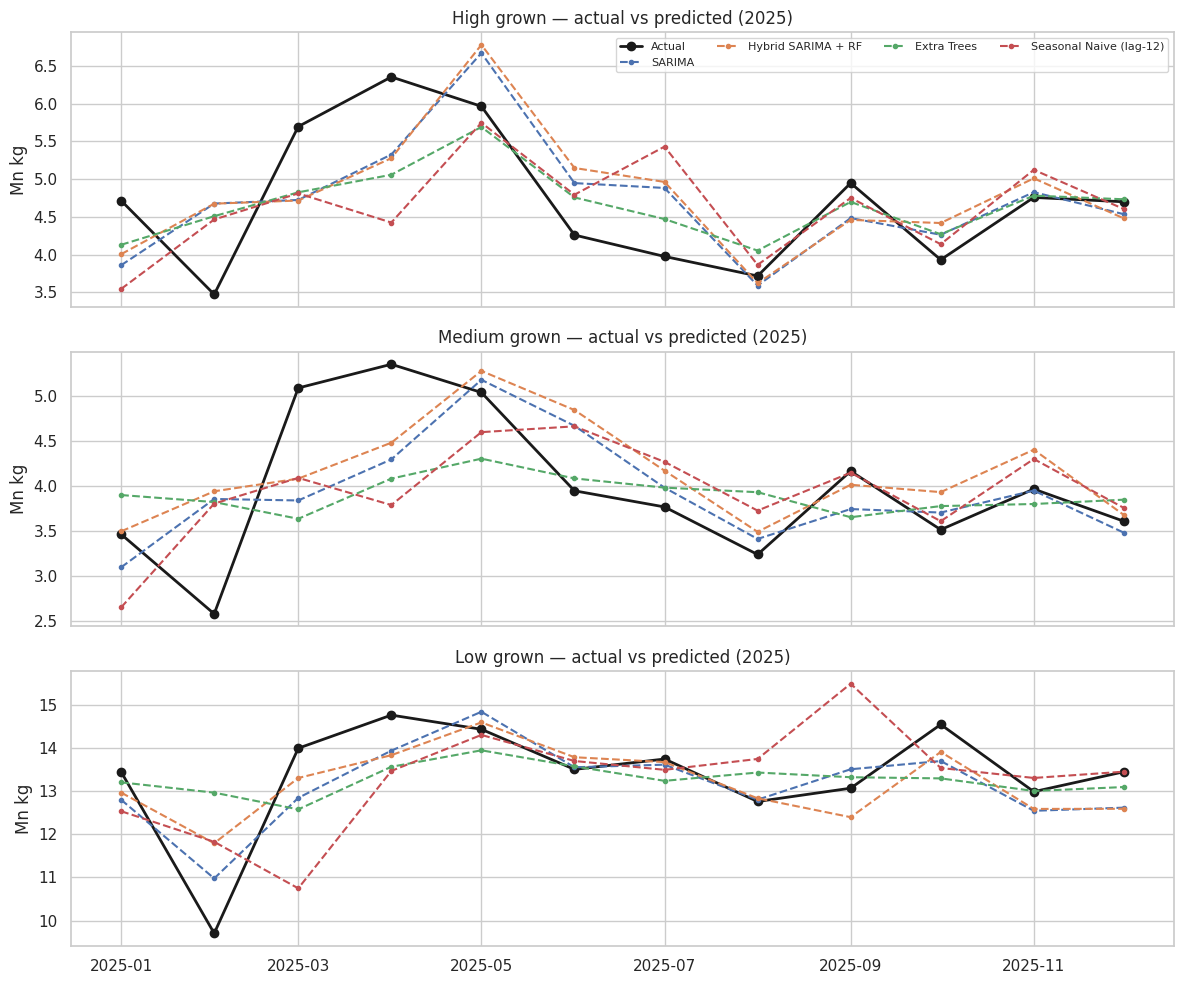

In [ ]:
best = results.index[:3].tolist()
fig, axes = plt.subplots(3, 1, figsize=(12,10), sharex=True)
for ax, e in zip(axes, ['High','Medium','Low']):
    g = pred[pred.Elevation==e]
    ax.plot(g.Date, g.Actual, 'k-o', lw=2, label='Actual')
    for m in best + ['Seasonal Naive (lag-12)']:
        ax.plot(g.Date, g[m], '--', marker='.', label=m)
    ax.set_title(f'{e} grown — actual vs predicted (2025)'); ax.set_ylabel('Mn kg')
axes[0].legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

## 8. Why do the models behave this way? — feature importance
Permutation importance: how much the 2025 RMSE increases when one feature is randomly shuffled.

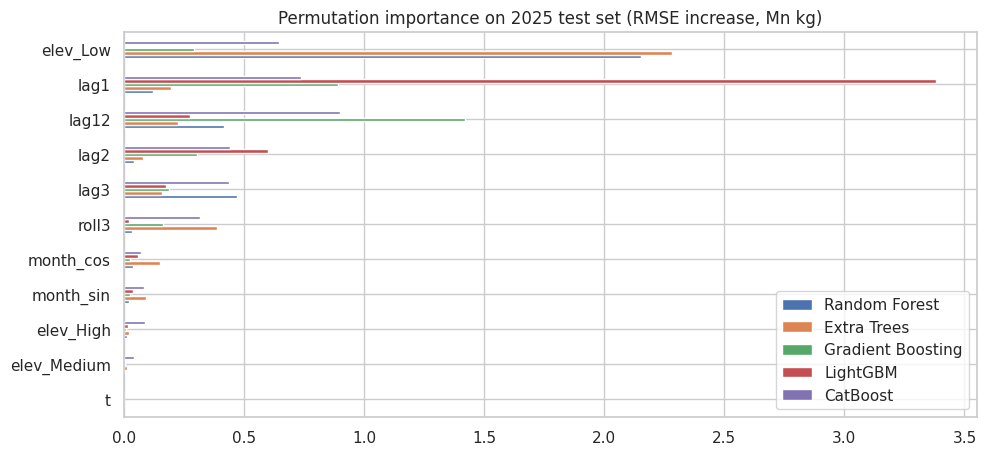

,Random Forest,Extra Trees,Gradient Boosting,LightGBM,CatBoost
lag1,0.118,0.196,0.889,3.382,0.738
lag2,0.039,0.079,0.303,0.601,0.439
lag3,0.469,0.158,0.187,0.176,0.438
lag12,0.414,0.224,1.420,0.274,0.900
roll3,0.034,0.386,0.163,0.021,0.315
month_sin,0.022,0.091,0.022,0.035,0.083
month_cos,0.038,0.148,0.023,0.056,0.070
t,0.000,0.000,0.000,0.000,0.000
elev_High,0.011,0.021,0.007,0.017,0.087
elev_Medium,0.003,0.014,0.004,0.002,0.041


In [ ]:
from sklearn.inspection import permutation_importance
IMP_MODELS = ['Random Forest','Extra Trees','Gradient Boosting','LightGBM','CatBoost']
imp_df = pd.DataFrame({n: pd.Series(permutation_importance(fitted[n], X_te, y_te, n_repeats=20, random_state=SEED,
                                    scoring='neg_root_mean_squared_error').importances_mean, index=FEATURES)
                       for n in IMP_MODELS})
fig, ax = plt.subplots(figsize=(11,5))
imp_df.loc[imp_df.mean(axis=1).sort_values().index].plot(kind='barh', ax=ax)
ax.set_title('Permutation importance on 2025 test set (RMSE increase, Mn kg)'); plt.show()
imp_df.round(3)

## 9. Final models and January 2026 forecast
All models are re-trained on **all** data up to Dec 2025, then forecast the next month.

In [ ]:
X_all, y_all = data[FEATURES], data.Prod
final = {name: clone(m).fit(X_all, y_all) for name, m in MODELS.items()}

def make_row(elev, month, lag1, lag2, lag3, lag12, t=60):
    return pd.DataFrame([{'lag1':lag1, 'lag2':lag2, 'lag3':lag3, 'lag12':lag12, 'roll3':(lag1+lag2+lag3)/3,
                          'month_sin':np.sin(2*np.pi*month/12), 'month_cos':np.cos(2*np.pi*month/12), 't':t,
                          **{f'elev_{k}': int(k==elev) for k in ['High','Medium','Low']}}])[FEATURES]

hist = long.set_index(['Elevation','Date'])['Prod']
X_next = pd.concat([make_row(e, 1, hist[e]['2025-12-01'], hist[e]['2025-11-01'], hist[e]['2025-10-01'], hist[e]['2025-01-01'])
                    for e in ['High','Medium','Low']], ignore_index=True)
fc = pd.DataFrame(index=['High','Medium','Low'])
fc['Seasonal Naive (lag-12)'] = X_next.lag12.values
for name, m in final.items():
    fc[name] = m.predict(X_next)
sar_next = [float(sarima((df.set_index('Date')[e]/1e6).asfreq('MS')).fit(disp=False).forecast(1).iloc[0]) for e in ['High','Medium','Low']]
fc['SARIMA'] = sar_next
rf_resid_final = new_resid_rf().fit(X_all, y_all.values - sarima_for(data))
fc['Hybrid SARIMA + RF'] = np.array(sar_next) + rf_resid_final.predict(X_next)
fc = fc.T
fc['Total'] = fc.sum(axis=1)
print('Forecast for January 2026 (Mn kg):')
fc.loc[results.index].round(2)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Forecast for January 2026 (Mn kg):


,High,Medium,Low,Total
SARIMA,4.71,3.35,13.50,21.56
Hybrid SARIMA + RF,4.64,3.55,13.75,21.94
Extra Trees,4.31,3.57,13.23,21.11
CatBoost,4.47,3.29,12.98,20.74
LightGBM,4.46,3.77,14.36,22.59
Gradient Boosting,4.61,3.58,13.71,21.89
Random Forest,4.78,3.73,13.35,21.87
Stacking (RF+GB+LGBM+Cat→Ridge),4.65,3.44,13.03,21.13
Seasonal Naive (lag-12),4.72,3.46,13.45,21.63
ANN (MLP),5.01,3.44,13.59,22.04


## 10. Export the trained models for the local dashboard
Saves the final models and all results into `tea_model_bundle.zip` and downloads it. Unzip it next to `app.py` so there is a folder named `tea_model_bundle`.

In [ ]:
B = 'tea_model_bundle'
os.makedirs(B, exist_ok=True)
joblib.dump(final, f'{B}/ml_models.joblib', compress=3)     # 7 trained ML models (used by the "Try a prediction" tab)
results.to_csv(f'{B}/results.csv'); by_elev.to_csv(f'{B}/results_by_elevation.csv', index=False)
pred.to_csv(f'{B}/predictions_2025.csv', index=False); imp_df.to_csv(f'{B}/feature_importance.csv')
fc.to_csv(f'{B}/forecast_2026_01.csv')
json.dump({'features': FEATURES, 'family': FAMILY, 'versions': VERSIONS,
           'final_models_trained_on': 'Jan 2022 - Dec 2025', 'test_period': '2025',
           'created': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')}, open(f'{B}/meta.json','w'), indent=2)
shutil.make_archive(B, 'zip', B)
print(os.listdir(B)); print('Zip size: %.1f MB' % (os.path.getsize(B+'.zip')/1e6))
print('Library versions to install locally:', VERSIONS)
try:
    from google.colab import files; files.download(B+'.zip')
except Exception as e:
    print('Download it from the Files panel on the left:', e)

['forecast_2026_01.csv', 'results.csv', 'feature_importance.csv', 'results_by_elevation.csv', 'meta.json', 'predictions_2025.csv', 'ml_models.joblib']
Zip size: 3.8 MB
Library versions to install locally: {'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'statsmodels': '0.15.0'}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Interpretation and conclusion

### Which model won?
On the unseen 2025 test year, **SARIMA was the best overall model: RMSE 0.700 Mn kg, MAPE 10.4%**. That is about **35% lower error than the seasonal naive baseline**, which simply repeats last year's value: RMSE 1.081. The **Hybrid SARIMA + RF** came second at 0.745. The best ensemble models were **Extra Trees** at 0.890 for bagging and **CatBoost** at 0.894 for boosting, followed by LightGBM at 0.944, Gradient Boosting at 0.961 and Random Forest at 0.966. **Stacking** scored 1.049, and the **ANN** was the weakest at 1.242.

The winner changes by elevation, which is the most interesting result:
- **High grown:** Extra Trees was best, RMSE 0.627, beating SARIMA at 0.727.
- **Medium grown:** CatBoost was best, 0.602, with Gradient Boosting at 0.647 and the hybrid at 0.652.
- **Low grown:** SARIMA was far ahead at 0.708, while every tree model scored between 1.18 and 1.38.

So the overall ranking is decided by **Low grown tea**, which is about 61% of national production and has the largest swings.

### Why do the models behave this way?
1. **Trees cannot extrapolate.** Random Forest, Extra Trees and the boosting models predict by averaging values they saw in training. When Low grown output moved outside its usual range in 2025, for example the sharp drop in February 2025 and the jump in March, the trees could not follow. SARIMA models the seasonal pattern directly through seasonal differencing, so it predicts the change relative to the same month last year and handled these swings better.
2. **Feature importance explains the boosting differences.** Permutation importance shows that `lag1`, last month, and `lag12`, the same month last year, carry most of the signal. LightGBM depended very heavily on `lag1`, so one unusual month pushed its next forecast off course. CatBoost and Random Forest spread their importance more evenly across `lag1`, `lag3` and `lag12`, which made them more stable. The time trend `t` had no importance, so the models found no steady trend after the 2022 crisis.
3. **Bagging versus boosting on small data.** With only 108 training rows, bagging reduces variance by averaging many trees, which suits small, noisy data. Extra Trees adds random split points, which smooths predictions even more, so it beat Random Forest. Boosting reduces bias by correcting mistakes step by step, but on small data it can fit noise. CatBoost did best among the boosters because its ordered boosting and symmetric trees act as built-in regularisation.
4. **Stacking did not help.** With RMSE 1.049, the stacked model was worse than each of its four base models. They are all tree models trained on the same lag features, so their errors are highly correlated and the Ridge meta-learner has little to combine. Five cross-validation folds on 108 time-ordered rows also give the meta-learner very little data to learn its weights.
5. **The hybrid.** SARIMA + RF lets SARIMA capture trend and seasonality while the RF learns SARIMA's residuals. It improved Medium grown slightly, 0.652 against 0.663, but was a little worse overall. After SARIMA, the remaining residuals are mostly random noise, and the RF partly fitted that noise.
6. **The neural network performed worst** because about a hundred rows is far too little data for an MLP to learn a reliable pattern.

### Note on R²
The overall R² values of about 0.92 to 0.97 look very high because the three elevations are pooled, and they differ greatly in size: Low grown is around 13 Mn kg a month, High and Medium around 4 to 5. RMSE and MAPE by elevation are the fairer comparison.

### Limitations and future work
- Only 60 months of data, 2021 to 2025. The 2022 fertiliser crisis also sits inside the training period.
- The forecasts are one month ahead only, and use past production alone.
- Next steps: add monthly rainfall and temperature for tea-growing districts, Colombo auction prices and the exchange rate as features; tune hyperparameters with time-series cross-validation; and use more years of data.

### Conclusion
For forecasting Sri Lankan tea production, **a seasonal time-series model was the most reliable overall**, while **ensemble models were best for the smaller High and Medium grown series**: bagging for High, boosting for Medium. A practical system would choose the model per elevation, which is what the Streamlit dashboard is designed to compare.